# AlphaWind data analysis

## 1. Introduction

### Data overview

| Dataset              | Description                             | Granularity            |
|----------------------|-----------------------------------------|------------------------|
| production.csv       | Energy production per turbine           | 10 minutes             |
| weather.csv          | Wind speed measurements                 | Park level, 10 minutes |
| stops_log.csv        | Operational stop and event records      | Event level            |
| turbine_metadata.csv | Turbine information and service history | Turbine level          |

All datasets cover the same 7-day period.

### Variables

production.csv - data about energy production per turbine
- timestamp
- turbine_id
- energy_kwh

stops_log.csv - data about each turbine stops
- timestamp_start
- timestamp_end
- turbine_id
- stop_code
- comment

turbine_metadata.csv - technical data about the turbines
- turbine_id
- park
- country
- model
- last_service_days_ago

weather.csv - windspeed data
- timestamp
- wind_speed_ms

### Data limitations

The stop log is not fully reliable. It contains:

- Missing event end timestamps.
- Duplicate event records.
- Incomplete reporting of park-level events across individual turbines.

### Goal of the analysis

Investigate the available data, identify the main drivers of production losses and develop an understanding of what happened during the period.

### Key findings

Overall:
- energy production is growing steeply when the wind speed is increasing, until the energy production reaches 250 kWh per 10 min
- The whole park ratio of actual / expected energy production is 0.991 (during time without stops)
- Double counting is avoided by calculating losses per turbine and 10-minute interval and assigning each interval exactly one cause, duplicates were removed, no intervals had overlapping events

Needs service:
- Turbines with the lowest ratio of actual / expected energy production: T04 (0.912) and T06 (0.984) had the longest time since their last service (120 and 65 days).
- T05 ran at 72–75% of expected output for ~1.5 hours, despite being serviced 18 days ago. Otherwise it performed as expected, worth checking if additional service is needed
- T04 lost 4.5 hours of performance due to a fault - 3 stops (its service was long time ago - points to a need of service). Had the worst performance while running
- T06's performance was the second worst, and since the last service was 65 days ago, this can point to the need of the maintenance, but the T04 service is a priority

Park level:
- There was 10.3 % less energy produced than expected
- The most energy production was lost due to factors that are not in control - high winds (46.8%) and grid limitations (33.1%).
- Technical faults and scheduled maintenance caused 14% of energy loss.
- The whole park is shut down when the wind is >25 m/s for more than 10 mins.

| Cause                         |   Estimated energy loss (kWh) |
|:------------------------------|------------------------------:|
| Extreme wind conditions (WND) |                         34845 |
| Grid limitation (GRD)         |                         24665 |
| Technical faults (FLT)        |                          6547 |
| Scheduled maintenance (MTN)   |                          3864 |
| Unexplained                   |                          4567 |
| Total                         |                         74488 |

## 2. Importing the data

In [1]:
import os

import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import duckdb
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch
from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

In [2]:
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

df_prod = pd.read_csv(DATA / "production.csv", parse_dates=["timestamp"])
df_weather = pd.read_csv(DATA / "weather.csv", parse_dates=["timestamp"])
df_stops = pd.read_csv(DATA / "stops_log.csv", parse_dates=["timestamp_start", "timestamp_end"])
df_turb = pd.read_csv(DATA / "turbine_metadata.csv")

In [3]:
df_prod.head()

,timestamp,turbine_id,energy_kwh
0,2026-03-01 00:00:00,T01,81.98
1,2026-03-01 00:10:00,T01,104.79
2,2026-03-01 00:20:00,T01,94.30
3,2026-03-01 00:30:00,T01,132.86
4,2026-03-01 00:40:00,T01,237.53


In [4]:
df_stops.head()

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
0,2026-03-02 01:30:00,2026-03-02 03:00:00,T02,FLT,Hydraulic technical fault #1
1,2026-03-02 06:40:00,2026-03-02 08:10:00,T04,FLT,Hydraulic technical fault #1
2,2026-03-03 11:50:00,2026-03-03 14:50:00,T06,MTN,Scheduled maintenance
3,2026-03-03 23:20:00,2026-03-04 00:50:00,T03,FLT,Hydraulic technical fault #1
4,2026-03-04 09:00:00,2026-03-04 11:00:00,T01,GRD,Park-level grid limitation


| Code | Meaning                 | Scope         |
|------|-------------------------|---------------|
| WND  | Extreme wind conditions | Park level    |
| GRD  | Grid limitation         | Park level    |
| FLT  | Technical turbine fault | Turbine level |
| MTN  | Scheduled maintenance   | Turbine level |

In [5]:
df_turb.sort_values(by="last_service_days_ago")

,turbine_id,park,country,model,last_service_days_ago
2,T03,AlphaWind,LT,V112,5
0,T01,AlphaWind,LT,V112,12
4,T05,AlphaWind,LT,V112,18
1,T02,AlphaWind,LT,V112,40
5,T06,AlphaWind,LT,V112,65
3,T04,AlphaWind,LT,V112,120


In [6]:
df_weather.head()

,timestamp,wind_speed_ms
0,2026-03-01 00:00:00,8.33
1,2026-03-01 00:10:00,9.00
2,2026-03-01 00:20:00,8.78
3,2026-03-01 00:30:00,9.67
4,2026-03-01 00:40:00,11.85


## 3. Checking data quality and exploring the data 

Checking if the data is complete

In [7]:
dfs = {
    "df_prod": df_prod,
    "df_stops": df_stops,
    "df_turb": df_turb,
    "df_weather": df_weather,
}

In [8]:
for name, df in dfs.items():
    print(f"Dataframe: {name}")
    print(f"Shape: {df.shape}")
    print(f"Duplicate rows: {df.duplicated().sum()}")
    print("Missing values per column:")
    print(df.isna().sum()[df.isna().sum() > 0])
    print()

Dataframe: df_prod
Shape: (6048, 3)
Duplicate rows: 0
Missing values per column:
Series([], dtype: int64)

Dataframe: df_stops
Shape: (38, 5)
Duplicate rows: 1
Missing values per column:
timestamp_end    4
dtype: int64

Dataframe: df_turb
Shape: (6, 5)
Duplicate rows: 0
Missing values per column:
Series([], dtype: int64)

Dataframe: df_weather
Shape: (1008, 2)
Duplicate rows: 0
Missing values per column:
Series([], dtype: int64)



- Duplicate rows in stops dataframe - dropping these rows
- Missing values in the stop end - fixing them later on

In [9]:
df_stops = df_stops.drop_duplicates()

Checking if the data types are correct

In [10]:
for name, df in dfs.items():
    print(f"Dataframe: {name}")
    print(f"Data types:\n{df.dtypes}")
    print()

Dataframe: df_prod
Data types:
timestamp     datetime64[us]
turbine_id               str
energy_kwh           float64
dtype: object

Dataframe: df_stops
Data types:
timestamp_start    datetime64[us]
timestamp_end      datetime64[us]
turbine_id                    str
stop_code                     str
comment                       str
dtype: object

Dataframe: df_turb
Data types:
turbine_id                 str
park                       str
country                    str
model                      str
last_service_days_ago    int64
dtype: object

Dataframe: df_weather
Data types:
timestamp        datetime64[us]
wind_speed_ms           float64
dtype: object



Checking the length of the data frames - production and weather data should have 7 days x 1440 minutes / 10 = 1008 rows of data

In [11]:
len(df_weather)

1008

In [12]:
df_prod.groupby("turbine_id").size()

turbine_id
T01    1008
T02    1008
T03    1008
T04    1008
T05    1008
T06    1008
dtype: int64

Now let's move on to the data exploration. Checking the maximum energy generated per 10mins for each turbine

In [13]:
df_prod.groupby(by="turbine_id").max()

,timestamp,energy_kwh
turbine_id,,
T01,2026-03-07 23:50:00,250.00
T02,2026-03-07 23:50:00,246.25
T03,2026-03-07 23:50:00,251.25
T04,2026-03-07 23:50:00,225.00
T05,2026-03-07 23:50:00,252.50
T06,2026-03-07 23:50:00,247.50


Energy generated versus the wind speed + stops marked

In [14]:
STOP_COLORS = {"WND": "#d9534f", "GRD": "#8e6bbf", "MTN": "#5cb85c", "FLT": "#555555"}

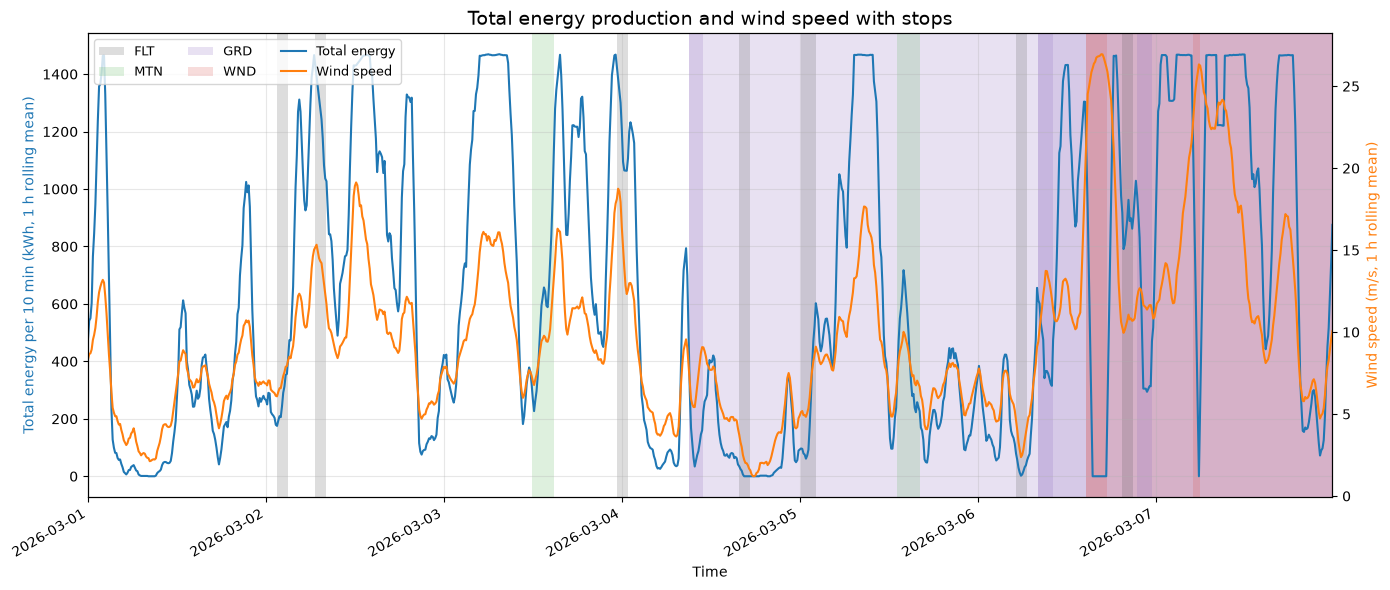

In [15]:
df_prod["timestamp"] = pd.to_datetime(df_prod["timestamp"])
df_weather["timestamp"] = pd.to_datetime(df_weather["timestamp"])

total = df_prod.groupby("timestamp")["energy_kwh"].sum().sort_index()
wind = df_weather.set_index("timestamp")["wind_speed_ms"].sort_index()

total_1h = total.rolling("1h").mean()
wind_1h = wind.rolling("1h").mean()

stops = df_stops.drop_duplicates(subset=["timestamp_start", "stop_code", "turbine_id"]).copy()
stops[["timestamp_start", "timestamp_end"]] = stops[["timestamp_start", "timestamp_end"]].apply(pd.to_datetime)
stops["timestamp_end"] = stops["timestamp_end"].fillna(total.index.max())
stops = stops.drop_duplicates(subset=["timestamp_start", "timestamp_end", "stop_code"])

fig, ax1 = plt.subplots(figsize=(14, 6))

labelled = set()
for _, s in stops.iterrows():
    code = s["stop_code"]
    ax1.axvspan(s["timestamp_start"], s["timestamp_end"],
                color=STOP_COLORS.get(code, "grey"), alpha=0.2, linewidth=0,
                label=code if code not in labelled else None)
    labelled.add(code)

ax1.plot(total_1h.index, total_1h.values, color="tab:blue", linewidth=1.5, label="Total energy")
ax1.set_ylabel("Total energy per 10 min (kWh, 1 h rolling mean)", color="tab:blue")
ax1.set_xlabel("Time")

ax2 = ax1.twinx()
ax2.plot(wind_1h.index, wind_1h.values, color="tab:orange", linewidth=1.5, label="Wind speed")
ax2.set_ylabel("Wind speed (m/s, 1 h rolling mean)", color="tab:orange")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", ncol=3, fontsize=9)

ax1.set_xlim(total.index.min(), total.index.max())
ax1.set_title("Total energy production and wind speed with stops", fontsize=14)
ax1.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

- several stops don't have end time
- energy production line follows the wind speed line
- there are stops not marked, due to the low winds

## 4. Data cleaning

Fixing four missing end marks - all of them are about park level stops, so should be for all turbines

In [16]:
df_stops[df_stops["timestamp_end"].isna()]

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
9,2026-03-04 09:00:00,NaT,T06,GRD,Park-level grid limitation
15,2026-03-06 08:10:00,NaT,T03,GRD,Park-level grid limitation
22,2026-03-06 14:40:00,NaT,T04,WND,High wind shutdown
24,2026-03-06 14:40:00,NaT,T06,WND,High wind shutdown


In [17]:
df_stops[df_stops["timestamp_start"] == "2026-03-04 09:00:00"]

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
4,2026-03-04 09:00:00,2026-03-04 11:00:00,T01,GRD,Park-level grid limitation
5,2026-03-04 09:00:00,2026-03-04 11:00:00,T02,GRD,Park-level grid limitation
6,2026-03-04 09:00:00,2026-03-04 11:00:00,T03,GRD,Park-level grid limitation
7,2026-03-04 09:00:00,2026-03-04 11:00:00,T04,GRD,Park-level grid limitation
8,2026-03-04 09:00:00,2026-03-04 11:00:00,T05,GRD,Park-level grid limitation
9,2026-03-04 09:00:00,NaT,T06,GRD,Park-level grid limitation


In [18]:
mask = (df_stops["timestamp_start"] == "2026-03-04 09:00:00") & (df_stops["turbine_id"] == "T06")
df_stops.loc[mask, "timestamp_end"] = pd.Timestamp("2026-03-04 11:00:00")

In [19]:
df_stops[df_stops["timestamp_start"] == "2026-03-04 09:00:00"]

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
4,2026-03-04 09:00:00,2026-03-04 11:00:00,T01,GRD,Park-level grid limitation
5,2026-03-04 09:00:00,2026-03-04 11:00:00,T02,GRD,Park-level grid limitation
6,2026-03-04 09:00:00,2026-03-04 11:00:00,T03,GRD,Park-level grid limitation
7,2026-03-04 09:00:00,2026-03-04 11:00:00,T04,GRD,Park-level grid limitation
8,2026-03-04 09:00:00,2026-03-04 11:00:00,T05,GRD,Park-level grid limitation
9,2026-03-04 09:00:00,2026-03-04 11:00:00,T06,GRD,Park-level grid limitation


In [20]:
df_stops[df_stops["timestamp_start"] == "2026-03-06 08:10:00"]

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
14,2026-03-06 08:10:00,2026-03-06 10:10:00,T01,GRD,Park-level grid limitation
15,2026-03-06 08:10:00,NaT,T03,GRD,Park-level grid limitation
16,2026-03-06 08:10:00,2026-03-06 10:10:00,T04,GRD,Park-level grid limitation
17,2026-03-06 08:10:00,2026-03-06 10:10:00,T05,GRD,Park-level grid limitation
18,2026-03-06 08:10:00,2026-03-06 10:10:00,T06,GRD,Park-level grid limitation


In [21]:
mask = (df_stops["timestamp_start"] == "2026-03-06 08:10:00") & (df_stops["turbine_id"] == "T03")
df_stops.loc[mask, "timestamp_end"] = pd.Timestamp("2026-03-06 10:10:00")

In [22]:
df_stops[df_stops["timestamp_start"] == "2026-03-06 08:10:00"]

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
14,2026-03-06 08:10:00,2026-03-06 10:10:00,T01,GRD,Park-level grid limitation
15,2026-03-06 08:10:00,2026-03-06 10:10:00,T03,GRD,Park-level grid limitation
16,2026-03-06 08:10:00,2026-03-06 10:10:00,T04,GRD,Park-level grid limitation
17,2026-03-06 08:10:00,2026-03-06 10:10:00,T05,GRD,Park-level grid limitation
18,2026-03-06 08:10:00,2026-03-06 10:10:00,T06,GRD,Park-level grid limitation


Was the T02 turbine also stopped during this time?

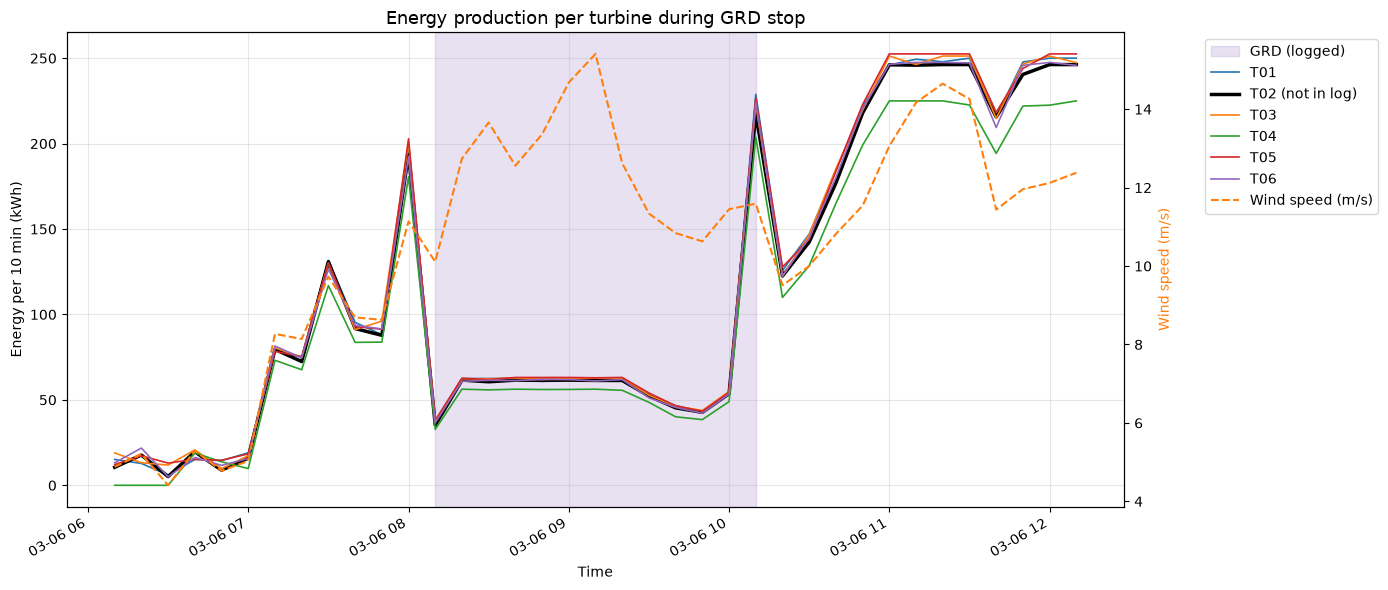

In [23]:
start = pd.Timestamp("2026-03-06 08:10:00")
end = pd.Timestamp("2026-03-06 10:10:00")
margin = pd.Timedelta("2h")

window = df_prod[df_prod["timestamp"].between(start - margin, end + margin)]
wind = df_weather[df_weather["timestamp"].between(start - margin, end + margin)]

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.axvspan(start, end, color="#8e6bbf", alpha=0.2, label="GRD (logged)")

for tid, t in window.groupby("turbine_id"):
    highlight = tid == "T02"
    ax1.plot(t["timestamp"], t["energy_kwh"],
             linewidth=2.5 if highlight else 1.2,
             color="black" if highlight else None,
             label=f"{tid}" + (" (not in log)" if highlight else ""))

ax1.set_ylabel("Energy per 10 min (kWh)")
ax1.set_xlabel("Time")

ax2 = ax1.twinx()
ax2.plot(wind["timestamp"], wind["wind_speed_ms"], color="tab:orange", linestyle="--",
         linewidth=1.5, label="Wind speed (m/s)")
ax2.set_ylabel("Wind speed (m/s)", color="tab:orange")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", bbox_to_anchor=(1.07, 1))

ax1.set_title("Energy production per turbine during GRD stop", fontsize=13)
ax1.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

Adding the stop for the T02 turbine as well

In [24]:
new_row = pd.DataFrame([{
    "timestamp_start": pd.Timestamp("2026-03-06 08:10:00"),
    "timestamp_end": pd.Timestamp("2026-03-06 10:10:00"),
    "turbine_id": "T02",
    "stop_code": "GRD",
    "comment": "Park-level grid limitation (added: missing from log)",
}])

df_stops = pd.concat([df_stops, new_row], ignore_index=True)
df_stops = df_stops.sort_values(["timestamp_start", "turbine_id"]).reset_index(drop=True)

In [25]:
df_stops[df_stops["timestamp_start"] == "2026-03-06 08:10:00"]

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
14,2026-03-06 08:10:00,2026-03-06 10:10:00,T01,GRD,Park-level grid limitation
15,2026-03-06 08:10:00,2026-03-06 10:10:00,T02,GRD,Park-level grid limitation (added: missing fro...
16,2026-03-06 08:10:00,2026-03-06 10:10:00,T03,GRD,Park-level grid limitation
17,2026-03-06 08:10:00,2026-03-06 10:10:00,T04,GRD,Park-level grid limitation
18,2026-03-06 08:10:00,2026-03-06 10:10:00,T05,GRD,Park-level grid limitation
19,2026-03-06 08:10:00,2026-03-06 10:10:00,T06,GRD,Park-level grid limitation


In [26]:
df_stops[df_stops["timestamp_start"] == "2026-03-06 14:40:00"]

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
20,2026-03-06 14:40:00,2026-03-06 17:30:00,T01,WND,High wind shutdown
21,2026-03-06 14:40:00,2026-03-06 17:30:00,T02,WND,High wind shutdown
22,2026-03-06 14:40:00,2026-03-06 17:30:00,T03,WND,High wind shutdown
23,2026-03-06 14:40:00,NaT,T04,WND,High wind shutdown
24,2026-03-06 14:40:00,2026-03-06 17:30:00,T05,WND,High wind shutdown
25,2026-03-06 14:40:00,NaT,T06,WND,High wind shutdown


In [27]:
mask = (df_stops["timestamp_start"] == "2026-03-06 14:40:00") & (df_stops["turbine_id"].isin(["T04", "T06"]))
df_stops.loc[mask, "timestamp_end"] = pd.Timestamp("2026-03-06 17:30:00")

In [28]:
df_stops[df_stops["timestamp_start"] == "2026-03-06 14:40:00"]

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
20,2026-03-06 14:40:00,2026-03-06 17:30:00,T01,WND,High wind shutdown
21,2026-03-06 14:40:00,2026-03-06 17:30:00,T02,WND,High wind shutdown
22,2026-03-06 14:40:00,2026-03-06 17:30:00,T03,WND,High wind shutdown
23,2026-03-06 14:40:00,2026-03-06 17:30:00,T04,WND,High wind shutdown
24,2026-03-06 14:40:00,2026-03-06 17:30:00,T05,WND,High wind shutdown
25,2026-03-06 14:40:00,2026-03-06 17:30:00,T06,WND,High wind shutdown


Redrawing the energy production and stops graph

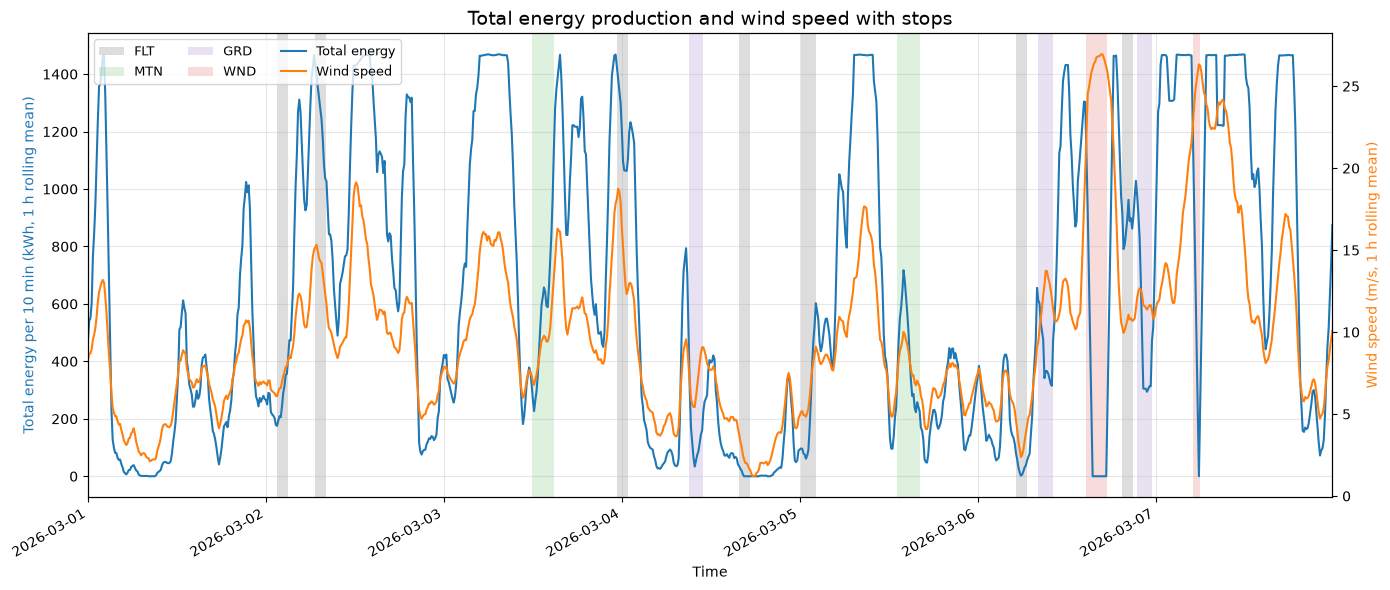

In [29]:
df_prod["timestamp"] = pd.to_datetime(df_prod["timestamp"])
df_weather["timestamp"] = pd.to_datetime(df_weather["timestamp"])

total = df_prod.groupby("timestamp")["energy_kwh"].sum().sort_index()
wind = df_weather.set_index("timestamp")["wind_speed_ms"].sort_index()

total_1h = total.rolling("1h").mean()
wind_1h = wind.rolling("1h").mean()

stops = df_stops.drop_duplicates(subset=["timestamp_start", "stop_code", "turbine_id"]).copy()
stops[["timestamp_start", "timestamp_end"]] = stops[["timestamp_start", "timestamp_end"]].apply(pd.to_datetime)
stops["timestamp_end"] = stops["timestamp_end"].fillna(total.index.max())
stops = stops.drop_duplicates(subset=["timestamp_start", "timestamp_end", "stop_code"])

fig, ax1 = plt.subplots(figsize=(14, 6))

labelled = set()
for _, s in stops.iterrows():
    code = s["stop_code"]
    ax1.axvspan(s["timestamp_start"], s["timestamp_end"],
                color=STOP_COLORS.get(code, "grey"), alpha=0.2, linewidth=0,
                label=code if code not in labelled else None)
    labelled.add(code)

ax1.plot(total_1h.index, total_1h.values, color="tab:blue", linewidth=1.5, label="Total energy")
ax1.set_ylabel("Total energy per 10 min (kWh, 1 h rolling mean)", color="tab:blue")
ax1.set_xlabel("Time")

ax2 = ax1.twinx()
ax2.plot(wind_1h.index, wind_1h.values, color="tab:orange", linewidth=1.5, label="Wind speed")
ax2.set_ylabel("Wind speed (m/s, 1 h rolling mean)", color="tab:orange")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", ncol=3, fontsize=9)

ax1.set_xlim(total.index.min(), total.index.max())
ax1.set_title("Total energy production and wind speed with stops", fontsize=14)
ax1.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

- now all the stop timeframes are distinct

Note: the stops due to low wind are not recorded as stops.

## 5. Expected energy production

To see how much energy was lost, first we have to see how much should be produced if everything goes right.

In [30]:
data = df_prod.merge(df_weather, on="timestamp", how="left")

MARGIN = pd.Timedelta("1h")
data["near_event"] = False
for _, s in df_stops.iterrows():
    end = s["timestamp_end"] if pd.notna(s["timestamp_end"]) else data["timestamp"].max()
    mask = ((data["turbine_id"] == s["turbine_id"]) &
            (data["timestamp"] >= s["timestamp_start"] - MARGIN) &
            (data["timestamp"] <= end + MARGIN))
    data.loc[mask, "near_event"] = True

CUT_IN = 3.0
clean = data[
    (~data["near_event"]) &
    (data["wind_speed_ms"] > CUT_IN) &
    (data["energy_kwh"] > 0)
]
print(f"Time intervals without events (plus margin): {len(clean)/len(data):.0%}")

Time intervals without events (plus margin): 79%


There is enough data without the stop events, from which we can see how much energy is usually produced during different levels of wind.

In [31]:
BIN = 0.5
clean = clean.assign(ws_bin=(clean["wind_speed_ms"] / BIN).round() * BIN)

curve = (clean.groupby("ws_bin")["energy_kwh"]
              .agg(expected_kwh="median", n="size")
              .reset_index())
curve = curve[curve["n"] >= 5]

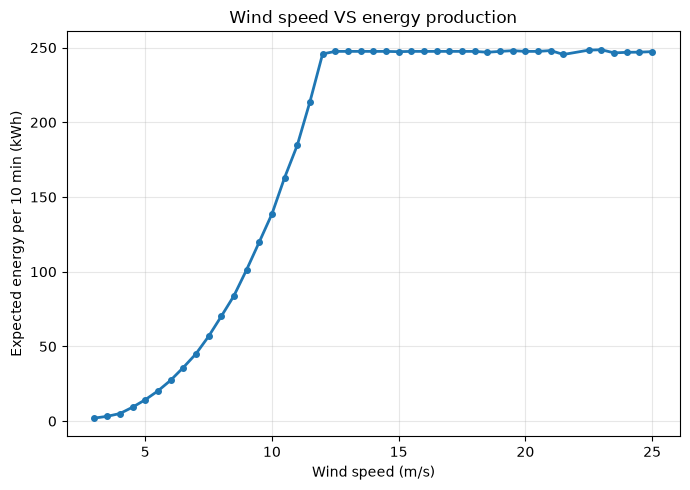

In [32]:
fig, ax = plt.subplots(figsize=(7,5))
ax.plot(curve["ws_bin"], curve["expected_kwh"], marker="o", markersize=4, linewidth=2)

ax.set_xlabel("Wind speed (m/s)")
ax.set_ylabel("Expected energy per 10 min (kWh)")
ax.set_title("Wind speed VS energy production")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The energy produced is growing steeply when the wind speed is increasing, until the energy production reaches 250 kWh per 10 min, this is the upper limit on what the turbine can produce.

In [33]:
RATED = clean["energy_kwh"].quantile(0.99)

def expected_energy(ws):
    e = np.interp(ws, curve["ws_bin"], curve["expected_kwh"])
    e = np.where(ws < CUT_IN, 0, e)
    e = np.where(ws >= curve["ws_bin"].max(), RATED, e)
    return np.minimum(e, RATED)

data["expected_kwh"] = expected_energy(data["wind_speed_ms"].values)

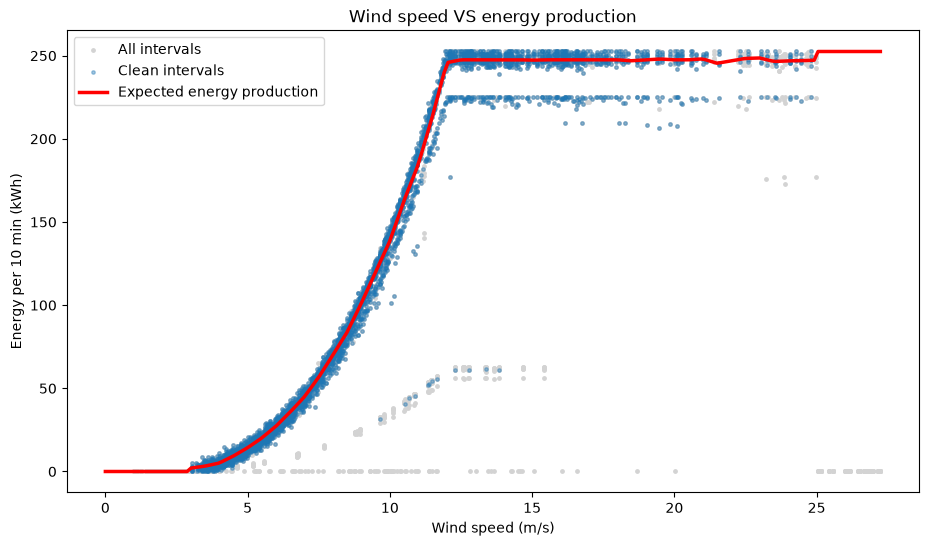

In [34]:
ws_grid = np.linspace(0, data["wind_speed_ms"].max(), 200)

fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(data["wind_speed_ms"], data["energy_kwh"], s=6, color="lightgrey", label="All intervals")
ax.scatter(clean["wind_speed_ms"], clean["energy_kwh"], s=6, color="tab:blue", alpha=0.4, label="Clean intervals")
ax.plot(ws_grid, expected_energy(ws_grid), color="red", linewidth=2.5, label="Expected energy production")
ax.set_xlabel("Wind speed (m/s)")
ax.set_ylabel("Energy per 10 min (kWh)")
ax.set_title("Wind speed VS energy production")
ax.legend()
plt.show()

- the most of the time the turbines produce more or less the amount of expected energy
- however, there are events where the energy production is below the expected level

In [35]:
c = data.loc[clean.index]
residual = c["energy_kwh"] - c["expected_kwh"]

print(f"Mean residual: {residual.mean():.1f} kWh")
print(f"Typical error (median absolute): {residual.abs().median():.1f} kWh per 10 min")
print(f"Actual and expected energy ratio on clean data: {c['energy_kwh'].sum() / c['expected_kwh'].sum():.3f}")
print(f"Typical error as % of mean expected: {residual.abs().median() / c['expected_kwh'].mean():.1%}")

Mean residual: -1.0 kWh
Typical error (median absolute): 2.5 kWh per 10 min
Actual and expected energy ratio on clean data: 0.991
Typical error as % of mean expected: 2.1%


On normal intervals the expected energy curve predicts about 1% more energy than the actual energy production. The typical error (2.1%) is small.

In [36]:
data.loc[clean.index].groupby("turbine_id").apply(lambda t: t["energy_kwh"].sum() / t["expected_kwh"].sum()).round(3)

turbine_id
T01    1.016
T02    0.994
T03    1.018
T04    0.912
T05    1.020
T06    0.984
dtype: float64

In [37]:
df_turb.sort_values(by="last_service_days_ago", ascending=False)

,turbine_id,park,country,model,last_service_days_ago
3,T04,AlphaWind,LT,V112,120
5,T06,AlphaWind,LT,V112,65
1,T02,AlphaWind,LT,V112,40
4,T05,AlphaWind,LT,V112,18
0,T01,AlphaWind,LT,V112,12
2,T03,AlphaWind,LT,V112,5


The whole park ratio of actual and expected energy production is 0.991, so the turbines T04 (0.912) and T06 (0.984) are below that. These are the turbines which have the most days since the last maintenance (120 days and 65 days respectively).

## 6. Energy loss calculation

Now we have the expected energy curve, so we can calculate the energy loss:
- threshold of 85% was chosen because energy production below this point would show the problems and not the normal noise
- minimal gap of 3 x 2.5 kWh is due to the typical error size (2.5 kWh) and the safety margin

In [38]:
THRESHOLD = 0.85
MIN_GAP = 3 * 2.5

data_end = data["timestamp"].max()
data["event"] = None

for _, s in df_stops.iterrows():
    end = s["timestamp_end"] if pd.notna(s["timestamp_end"]) else data_end
    mask = ((data["turbine_id"] == s["turbine_id"]) &
            (data["timestamp"] >= s["timestamp_start"].floor("10min")) &
            (data["timestamp"] < end.ceil("10min")))
    data.loc[mask, "event"] = s["stop_code"]

data["gap_kwh"] = data["expected_kwh"] - data["energy_kwh"]
data["clearly_low"] = (data["energy_kwh"] < THRESHOLD * data["expected_kwh"]) & (data["gap_kwh"] > MIN_GAP)

data["cause"] = np.where(data["event"].notna(), data["event"],
                np.where(data["clearly_low"], "Unexplained", "None"))
data["loss_kwh"] = np.where(data["cause"] != "None", data["gap_kwh"].clip(lower=0), 0)

expected, actual = data["expected_kwh"].sum(), data["energy_kwh"].sum()
table = (data.groupby("cause")["loss_kwh"].sum()
             .reindex(["WND", "GRD", "FLT", "MTN", "Unexplained"]).fillna(0)
             .to_frame("loss_kwh"))
table.loc["Total"] = table["loss_kwh"].sum()
table["% of loss"] = table["loss_kwh"] / table.loc["Total", "loss_kwh"] * 100
table["% of expected"] = table["loss_kwh"] / expected * 100
display(table.round(1))

,loss_kwh,% of loss,% of expected
cause,,,
WND,34845.0,46.8,4.8
GRD,24664.9,33.1,3.4
FLT,6546.7,8.8,0.9
MTN,3864.4,5.2,0.5
Unexplained,4566.8,6.1,0.6
Total,74487.8,100.0,10.3


- Each turbine stop got assigned only one cause to avoid double counting
- There was 10.3 % less energy produced than expected
- The most energy production was lost due to factors that are not in control - high winds (46.8%) and grid limitations (33.1%).
- Technical faults and scheduled maintenance caused 14% of energy loss.
- 6% of energy loss is not due to logged events

Exploring the unexplained losses - was it due to wind speed?

In [39]:
u = data[data["cause"] == "Unexplained"].copy()
bands = [0, 5, 10, 15, 20, 25, 30]

u["ws_band"] = pd.cut(u["wind_speed_ms"], bands)
summary = u.groupby("ws_band", observed=True).agg(
    intervals=("loss_kwh", "size"),
    loss_kwh=("loss_kwh", "sum"))
summary["% of unexplained"] = (summary["loss_kwh"] / summary["loss_kwh"].sum() * 100).round(1)
summary

,intervals,loss_kwh,% of unexplained
ws_band,,,
"(5, 10]",17,297.7287,6.5
"(10, 15]",19,2156.3731,47.2
"(15, 20]",7,271.6950,5.9
"(20, 25]",5,326.0168,7.1
"(25, 30]",6,1515.0000,33.2


It was both in moderate wind (15-20m/s) and during extreme winds (25-30m/s), so the low wind hypothesis rules out. Let's see what's the actual reason.

In [40]:
u = data[data["cause"] == "Unexplained"].copy()

u["turbine_ratio"] = u["energy_kwh"] / u["expected_kwh"]

totals = data.groupby("timestamp")[["energy_kwh", "expected_kwh"]].sum()
u = u.join(totals, on="timestamp", rsuffix="_park")
u["park_ratio"] = ((u["energy_kwh_park"] - u["energy_kwh"]) /
                   (u["expected_kwh_park"] - u["expected_kwh"]))
u = u.drop(columns=["energy_kwh_park", "expected_kwh_park"])

both = u[u["wind_speed_ms"].between(10, 15) | u["wind_speed_ms"].between(25, 30)]
both.sort_values("timestamp")[["timestamp", "turbine_id", "wind_speed_ms",
                               "energy_kwh", "expected_kwh", "turbine_ratio", "park_ratio"]].round(2)

,timestamp,turbine_id,wind_speed_ms,energy_kwh,expected_kwh,turbine_ratio,park_ratio
4828,2026-03-06 12:40:00,T05,10.16,105.50,146.44,0.72,1.00
4829,2026-03-06 12:50:00,T05,10.03,101.32,140.11,0.72,1.01
4830,2026-03-06 13:00:00,T05,10.95,135.41,182.51,0.74,1.00
4831,2026-03-06 13:10:00,T05,10.89,130.73,179.90,0.73,1.01
4832,2026-03-06 13:20:00,T05,10.82,132.46,176.87,0.75,1.01
4833,2026-03-06 13:30:00,T05,12.12,176.75,246.20,0.72,0.99
4834,2026-03-06 13:40:00,T05,11.19,140.56,195.73,0.72,1.01
4835,2026-03-06 13:50:00,T05,11.21,143.35,196.89,0.73,1.00
5889,2026-03-06 21:30:00,T06,13.85,60.93,247.50,0.25,0.25
5890,2026-03-06 21:40:00,T06,12.78,61.25,247.50,0.25,0.25


In [41]:
df_stops[df_stops["turbine_id"] == "T05"].sort_values("timestamp_start")

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
8,2026-03-04 09:00:00,2026-03-04 11:00:00,T05,GRD,Park-level grid limitation
18,2026-03-06 08:10:00,2026-03-06 10:10:00,T05,GRD,Park-level grid limitation
24,2026-03-06 14:40:00,2026-03-06 17:30:00,T05,WND,High wind shutdown
26,2026-03-06 19:30:00,2026-03-06 21:00:00,T05,FLT,Hydraulic technical fault #1
31,2026-03-06 21:30:00,2026-03-06 23:30:00,T05,GRD,Park-level grid limitation
36,2026-03-07 05:00:00,2026-03-07 06:00:00,T05,WND,High wind shutdown


- for the first case unexplained energy loss, I see that 5th turbine was producing less energy (72-75% capacity) than the whole park (about 100% capacity). this shows a turbine fault. 
- the service for this turbine was just 18 days ago
- after this reduced energy period there were high winds (high wind shut down) and later the turbine had a hydraulic technical fault. this could point to a need for maintenance for this turbine, because there is a possibility that high winds were one of the reasons for a turbine fault

Now let's see what happened with the T06 turbine.
- The energy production was 25% of the expected production, but so was for all of the park.
- This points to a park level grid limitation, which is confirmed by the stop information

In [42]:
w_start, w_end = pd.Timestamp("2026-03-06 21:00"), pd.Timestamp("2026-03-07 00:00")

df_stops[(df_stops["timestamp_start"] <= w_end) &
         (df_stops["timestamp_end"].fillna(w_end) >= w_start)].sort_values(["timestamp_start", "turbine_id"])

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
26,2026-03-06 19:30:00,2026-03-06 21:00:00,T05,FLT,Hydraulic technical fault #1
27,2026-03-06 21:30:00,2026-03-06 23:30:00,T01,GRD,Park-level grid limitation
28,2026-03-06 21:30:00,2026-03-06 23:30:00,T02,GRD,Park-level grid limitation
29,2026-03-06 21:30:00,2026-03-06 23:30:00,T03,GRD,Park-level grid limitation
30,2026-03-06 21:30:00,2026-03-06 23:30:00,T04,GRD,Park-level grid limitation
31,2026-03-06 21:30:00,2026-03-06 23:30:00,T05,GRD,Park-level grid limitation


New row for T06 turbine stop needs to be added, since it's a park level grid limitation.

In [43]:
new_row = pd.DataFrame([{
    "timestamp_start": pd.Timestamp("2026-03-06 21:30:00"),
    "timestamp_end": pd.Timestamp("2026-03-06 23:30:00"),
    "turbine_id": "T06",
    "stop_code": "GRD",
    "comment": "Park-level grid limitation (added: missing from log)",
}])

df_stops = pd.concat([df_stops, new_row], ignore_index=True)
df_stops = df_stops.sort_values(["timestamp_start", "turbine_id"]).reset_index(drop=True)

df_stops[df_stops["timestamp_start"] == "2026-03-06 21:30:00"]

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
27,2026-03-06 21:30:00,2026-03-06 23:30:00,T01,GRD,Park-level grid limitation
28,2026-03-06 21:30:00,2026-03-06 23:30:00,T02,GRD,Park-level grid limitation
29,2026-03-06 21:30:00,2026-03-06 23:30:00,T03,GRD,Park-level grid limitation
30,2026-03-06 21:30:00,2026-03-06 23:30:00,T04,GRD,Park-level grid limitation
31,2026-03-06 21:30:00,2026-03-06 23:30:00,T05,GRD,Park-level grid limitation
32,2026-03-06 21:30:00,2026-03-06 23:30:00,T06,GRD,Park-level grid limitation (added: missing fro...


Also, adding WND stop for no energy production during >25 m/s wind.

In [44]:
df_weather[df_weather["timestamp"].between("2026-03-07 08:00", "2026-03-07 08:40")]

,timestamp,wind_speed_ms
912,2026-03-07 08:00:00,23.25
913,2026-03-07 08:10:00,23.03
914,2026-03-07 08:20:00,25.17
915,2026-03-07 08:30:00,24.26
916,2026-03-07 08:40:00,24.06


There were just 10mins of high wind and stopped energy production. Still adding this as a stop.

In [45]:
turbines = ["T01", "T02", "T03", "T04", "T05", "T06"]
new_rows = pd.DataFrame([{
    "timestamp_start": pd.Timestamp("2026-03-07 08:20:00"),
    "timestamp_end": pd.Timestamp("2026-03-07 08:30:00"),
    "turbine_id": tid,
    "stop_code": "WND",
    "comment": "Extreme wind (added: wind > 25 m/s, all turbines at zero, no log entry)",
} for tid in turbines])

df_stops = pd.concat([df_stops, new_rows], ignore_index=True)
df_stops = df_stops.sort_values(["timestamp_start", "turbine_id"]).reset_index(drop=True)

Updating the energy loss table.

In [46]:
THRESHOLD = 0.85
MIN_GAP = 3 * 2.5

data_end = data["timestamp"].max()
data["event"] = None
for _, s in df_stops.iterrows():
    end = s["timestamp_end"] if pd.notna(s["timestamp_end"]) else data_end
    mask = ((data["turbine_id"] == s["turbine_id"]) &
            (data["timestamp"] >= s["timestamp_start"].floor("10min")) &
            (data["timestamp"] < end.ceil("10min")))
    data.loc[mask, "event"] = s["stop_code"]

data["gap_kwh"] = data["expected_kwh"] - data["energy_kwh"]
data["clearly_low"] = (data["energy_kwh"] < THRESHOLD * data["expected_kwh"]) & (data["gap_kwh"] > MIN_GAP)

data["cause"] = np.where(data["event"].notna(), data["event"],
                np.where(data["clearly_low"], "Unexplained", "None"))
data["loss_kwh"] = np.where(data["cause"] != "None", data["gap_kwh"].clip(lower=0), 0)

expected, actual = data["expected_kwh"].sum(), data["energy_kwh"].sum()
table = (data.groupby("cause")["loss_kwh"].sum()
             .reindex(["WND", "GRD", "FLT", "MTN", "Unexplained"]).fillna(0)
             .to_frame("loss_kwh"))
table.loc["Total"] = table["loss_kwh"].sum()
table["% of loss"] = table["loss_kwh"] / table.loc["Total", "loss_kwh"] * 100
table["% of expected"] = table["loss_kwh"] / expected * 100
display(table.round(1))

,loss_kwh,% of loss,% of expected
cause,,,
WND,36360.0,48.8,5.1
GRD,26517.5,35.6,3.7
FLT,6546.7,8.8,0.9
MTN,3864.4,5.2,0.5
Unexplained,1199.2,1.6,0.2
Total,74487.8,100.0,10.3


In [47]:
print(f"Expected {expected/1000:.1f} MWh | Actual {actual/1000:.1f} MWh | "
      f"Shortfall {(expected-actual)/1000:.1f} MWh | Attributed loss {data['loss_kwh'].sum()/1000:.1f} MWh")

Expected 719.8 MWh | Actual 642.3 MWh | Shortfall 77.5 MWh | Attributed loss 74.5 MWh


- 3368 kWh moved from Unexplained to logged causes: 1853 kWh to GRD (T06's missing record on 6 March) and 1515 kWh to WND (unlogged extreme-wind stop on 7 March 08:20)
- Unexplained dropped from 6.1% to 1.6% of total losses
- External causes (WND + GRD) now account for 84.4% of the loss, up from 79.9%
- The total loss is unchanged (74488 kWh), confirming the corrections only reassigned losses between causes

is 85% the right threshold?

In [48]:
for t in [0.80, 0.85, 0.90]:
    low = (data["energy_kwh"] < t * data["expected_kwh"]) & (data["gap_kwh"] > MIN_GAP)
    cause = np.where(data["event"].notna(), data["event"],
            np.where(low, "Unexplained", "None"))
    loss = pd.Series(np.where(cause != "None", data["gap_kwh"].clip(lower=0), 0)).groupby(cause).sum()
    print(f"{t:.0%}: Unexplained {loss.get('Unexplained', 0):.0f} kWh, total {loss.drop('None', errors='ignore').sum():.0f} kWh")

80%: Unexplained 726 kWh, total 74015 kWh
85%: Unexplained 1199 kWh, total 74488 kWh
90%: Unexplained 2888 kWh, total 76177 kWh


Above 85% threshold the unexpected loss rise drastically, so the 85% margin was chosen correctly.

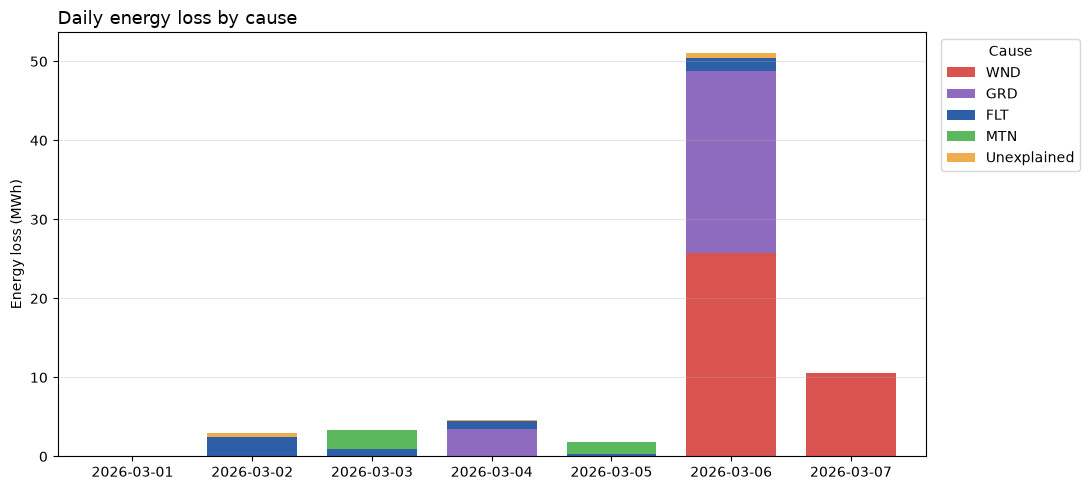

In [49]:
CAUSE_COLORS = {"WND": "#d9534f",
                "GRD": "#8e6bbf",
                "FLT": "#2c5fa8",
                "MTN": "#5cb85c",
                "Unexplained": "#f0ad4e"}

daily_loss = (data[data["cause"] != "None"]
              .pivot_table(index=data["timestamp"].dt.date, columns="cause",
                           values="loss_kwh", aggfunc="sum")
              .reindex(columns=CAUSE_COLORS, fill_value=0)
              .fillna(0) / 1000)

ax = daily_loss.plot(kind="bar", stacked=True, figsize=(11, 5),
                     color=[CAUSE_COLORS[c] for c in daily_loss.columns], width=0.75)
ax.set_xlabel("")
ax.set_ylabel("Energy loss (MWh)")
ax.set_title("Daily energy loss by cause", loc="left", fontsize=13)
ax.legend(title="Cause", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGS / "daily_loss_by_cause.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Turbine level performance

In [50]:
duckdb.sql("""
    SELECT turbine_id,
           stop_code,
           COUNT(*) AS n_stops,
           SUM(date_diff('minute', timestamp_start, timestamp_end)) / 60.0 AS total_hours
    FROM df_stops
    GROUP BY turbine_id, stop_code
    ORDER BY total_hours DESC
""").df() 

,turbine_id,stop_code,n_stops,total_hours
0,T05,GRD,3,6.0
1,T01,GRD,3,6.0
2,T03,GRD,3,6.0
3,T04,GRD,3,6.0
4,T06,GRD,3,6.0
5,T02,GRD,3,6.0
6,T04,FLT,3,4.5
7,T05,WND,3,4.0
8,T02,WND,3,4.0
9,T03,WND,3,4.0


- The most time was lost due to grid limitations and high wind conditions
- T04 lost 4.5 hours of performance due to a fault - 3 stops (its service was long time ago - points to a need of service)

In [51]:
PERIOD_START, PERIOD_END = df_prod["timestamp"].min(), df_prod["timestamp"].max()
PERIOD_HOURS = (PERIOD_END - PERIOD_START).total_seconds() / 3600

stops = df_stops.copy()
stops["end_filled"] = stops["timestamp_end"].fillna(PERIOD_END)
stops["start_c"] = stops["timestamp_start"].clip(PERIOD_START, PERIOD_END)
stops["end_c"] = stops["end_filled"].clip(PERIOD_START, PERIOD_END)
stops["duration_h"] = (stops["end_c"] - stops["start_c"]).dt.total_seconds() / 3600

daily = (df_prod.set_index("timestamp")
                .groupby("turbine_id")["energy_kwh"]
                .resample("1D").sum()
                .reset_index())

def turbine_summary(tid):
    p = df_prod[df_prod["turbine_id"] == tid]
    s = stops[stops["turbine_id"] == tid]
    d = daily[daily["turbine_id"] == tid]["energy_kwh"]
    downtime = s["duration_h"].sum()
    return {
        "turbine_id": tid,
        "total_mwh": p["energy_kwh"].sum() / 1000,
        "mean_daily_kwh": d.mean(),
        "median_daily_kwh": d.median(),
        "n_stops": len(s),
        "downtime_h": downtime,
        "availability_%": 100 * (1 - downtime / PERIOD_HOURS),
        **{f"{c}_h": s.loc[s["stop_code"] == c, "duration_h"].sum() for c in STOP_COLORS},
    }

summary = pd.DataFrame([turbine_summary(t) for t in sorted(df_prod["turbine_id"].unique())])
summary = summary.merge(df_turb, on="turbine_id", how="left")

energy_ratio = (data.groupby("turbine_id")
                    .apply(lambda t: t["energy_kwh"].sum() / t["expected_kwh"].sum() * 100)
                    .rename("energy_ratio_%"))

performance_ratio = (data.loc[clean.index]
                         .groupby("turbine_id")
                         .apply(lambda t: t["energy_kwh"].sum() / t["expected_kwh"].sum() * 100)
                         .rename("performance_ratio_%"))

summary = (summary
           .merge(energy_ratio, on="turbine_id", how="left")
           .merge(performance_ratio, on="turbine_id", how="left"))

summary[["turbine_id", "availability_%", "energy_ratio_%", "performance_ratio_%"]].round(1)

,turbine_id,availability_%,energy_ratio_%,performance_ratio_%
0,T01,92.9,92.4,101.6
1,T02,93.1,90.4,99.4
2,T03,93.1,91.2,101.8
3,T04,89.6,80.5,91.2
4,T05,93.1,91.4,102.0
5,T06,92.3,89.6,98.4


- availability - time running
- energy ratio - produced VS expected energy ratio (including stops)
- performance ratio - produced VS expected energy ratio (excluding stops)

In [52]:
wind_h = df_weather.set_index("timestamp")["wind_speed_ms"].sort_index().resample("1h").mean()

def turbine_card(tid):
    row = summary.set_index("turbine_id").loc[tid]
    prod_h = (df_prod[df_prod["turbine_id"] == tid].set_index("timestamp")["energy_kwh"]
              .sort_index().resample("1h").sum())
    s = stops[stops["turbine_id"] == tid]
    d = daily[daily["turbine_id"] == tid]
    park_daily_mean = daily.groupby("timestamp")["energy_kwh"].mean()

    fig = plt.figure(figsize=(16, 8))
    gs = GridSpec(2, 3, figure=fig, width_ratios=[1.4, 1, 0.8], height_ratios=[1.3, 1],
                  hspace=0.45, wspace=0.3)

    ax = fig.add_subplot(gs[0, :2])
    ax.plot(prod_h.index, prod_h.values, color="tab:blue", linewidth=0.8)
    ax.set_ylabel("Energy per hour (kWh)", color="tab:blue")
    for _, r in s.iterrows():
        ax.axvspan(r["start_c"], r["end_c"], color=STOP_COLORS.get(r["stop_code"], "grey"), alpha=0.25)
    axw = ax.twinx()
    axw.plot(wind_h.index, wind_h.values, color="tab:orange", linewidth=0.8, alpha=0.7)
    axw.set_ylabel("Wind speed (m/s)", color="tab:orange")
    axw.grid(False)
    ax.set_xlim(PERIOD_START, PERIOD_END)
    ax.set_title("Production, wind and stops", loc="left", fontsize=11)
    ax.legend(handles=[Patch(color=c, alpha=0.4, label=k) for k, c in STOP_COLORS.items()],
              loc="upper left", ncol=4, fontsize=8)

    ax_d = fig.add_subplot(gs[1, 0])
    ax_d.bar(d["timestamp"], d["energy_kwh"], width=0.8, color="tab:blue", alpha=0.8, label=f"Turbine {tid}")
    ax_d.plot(park_daily_mean.index, park_daily_mean.values, color="black",
              marker="o", markersize=4, linewidth=1, label="Park mean (all turbines)")
    ax_d.set_title("Daily energy (kWh)", loc="left", fontsize=11)
    ax_d.legend(fontsize=8)
    ax_d.tick_params(axis="x", rotation=30)


    ax_c = fig.add_subplot(gs[1, 1])
    hours = [row[f"{c}_h"] for c in STOP_COLORS]
    ax_c.barh(list(STOP_COLORS), hours, color=list(STOP_COLORS.values()))
    for y, h in enumerate(hours):
        ax_c.text(h, y, f" {h:.1f} h", va="center", fontsize=9)
    ax_c.set_title("Downtime by stop code", loc="left", fontsize=11)
    ax_c.set_xlim(0, max(max(hours) * 1.25, 1))

    ax_k = fig.add_subplot(gs[:, 2])
    ax_k.axis("off")
    service = (f"{int(row['last_service_days_ago'])} days ago"
               if pd.notna(row.get("last_service_days_ago")) else "unknown")
    kpis = [
        ("Mean daily", f"{row['mean_daily_kwh']:.0f} kWh"),
        ("Median daily", f"{row['median_daily_kwh']:.0f} kWh"),
        ("Stops", f"{int(row['n_stops'])}"),
        ("Availability (time)", f"{row['availability_%']:.1f} %"),
        ("Energy ratio (all)", f"{row['energy_ratio_%']:.1f} %"),
        ("Performance (running)", f"{row['performance_ratio_%']:.1f} %"),
    ]
    y = 0.95
    for label, value in kpis:
        ax_k.text(0, y, label, fontsize=10, color="grey", transform=ax_k.transAxes)
        ax_k.text(0, y - 0.045, value, fontsize=15, weight="bold", transform=ax_k.transAxes)
        y -= 0.13

    fig.suptitle(f"Turbine {tid}  |  Last service: {service}",
                 x=0.06, ha="left", fontsize=15, weight="bold")
    plt.show()

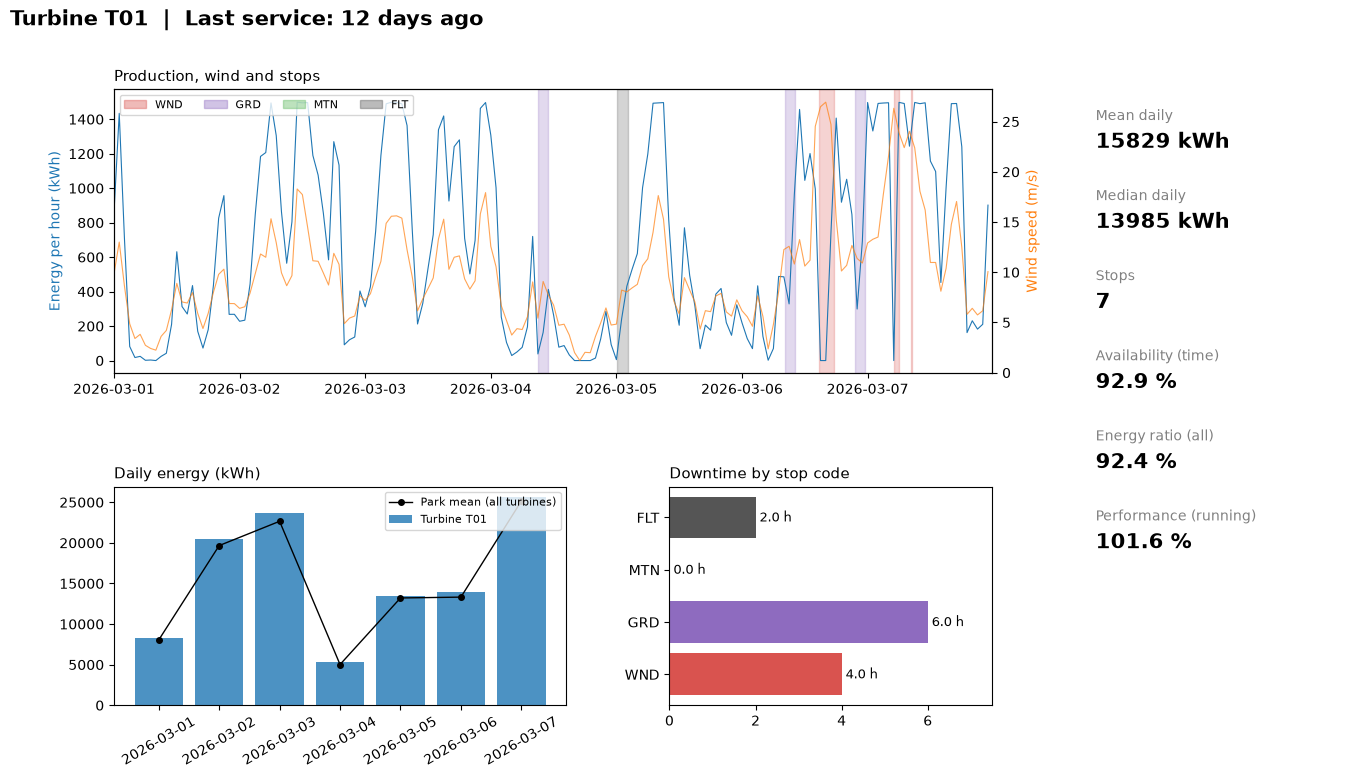

In [53]:
turbine_card("T01")

- T01 had the highest energy ratio during the whole period, including stops

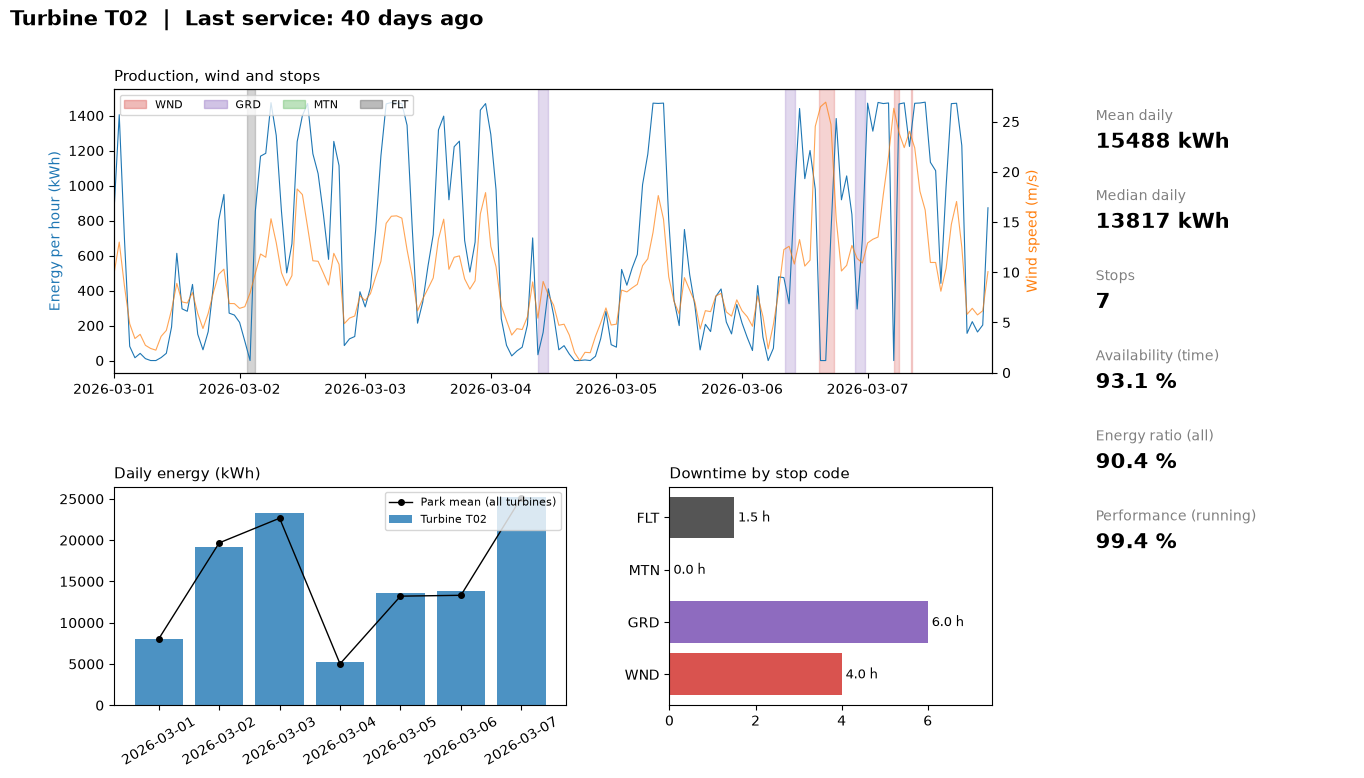

In [54]:
turbine_card("T02")

- T02, T03, T05 were performing similarly
- Turbine performance while running was near the expected energy

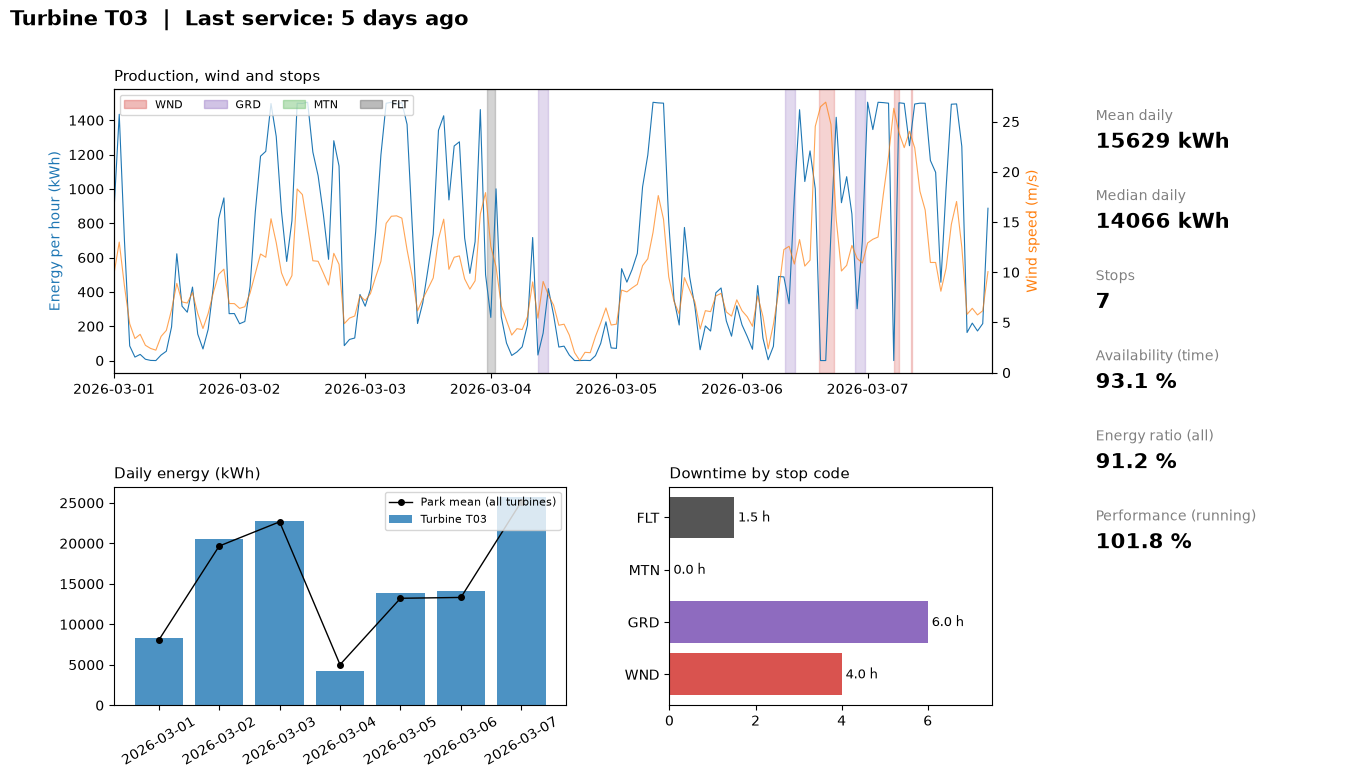

In [55]:
turbine_card("T03")

- T02, T03, T05 were performing similarly
- Turbine performance while running was near the expected energy

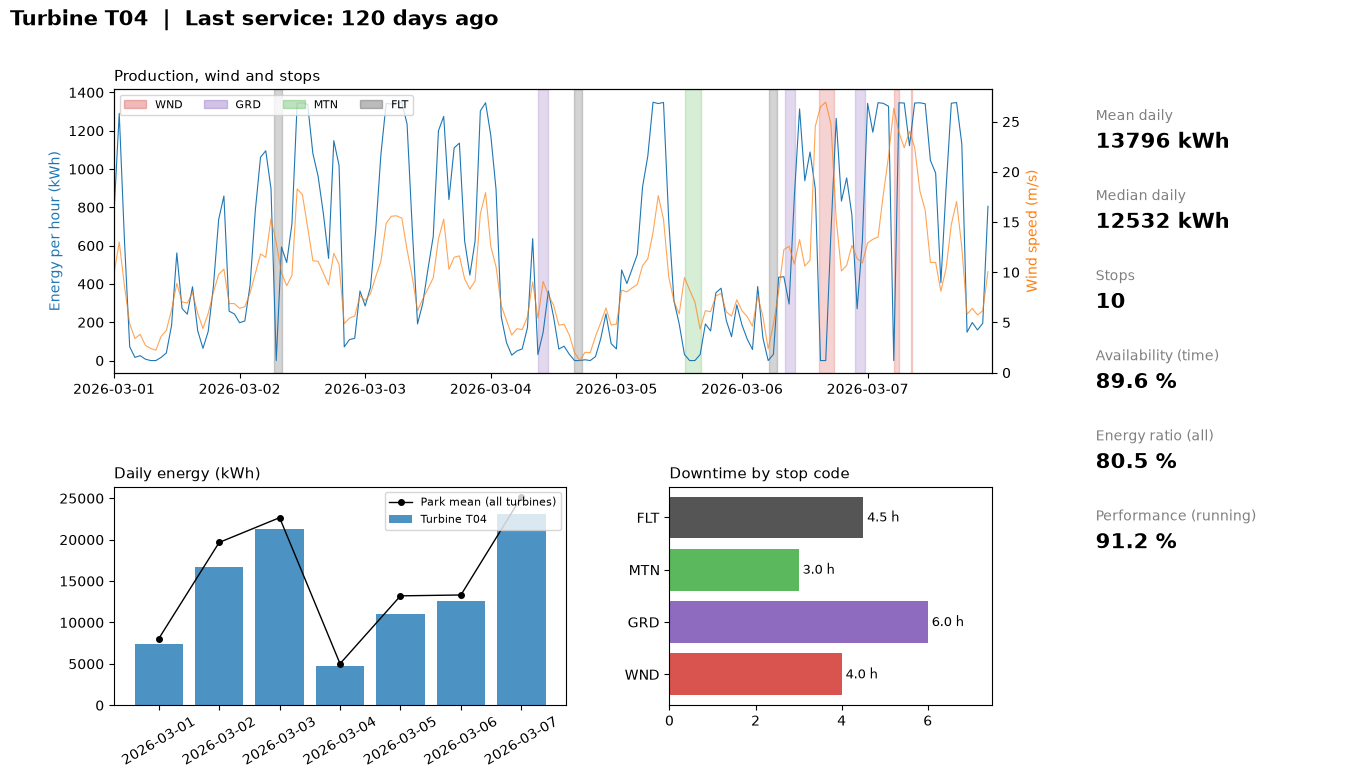

In [56]:
turbine_card("T04")

In [57]:
t04 = data.loc[clean.index]
t04 = t04[t04["turbine_id"] == "T04"]

t04_loss = (t04["expected_kwh"] - t04["energy_kwh"]).sum()
print(f"T04 underperformance loss: {t04_loss / 1000:,.1f} MWh "
      f"({t04_loss / t04['expected_kwh'].sum():.1%} of its expected production while running)")

T04 underperformance loss: 7.9 MWh (8.8% of its expected production while running)


- Was running the least time of all (9 stops), 4.5 hours lost due to faults (3 stops)
- Produced the least energy overall
- Had the worst performance while running
- These things point to the need of service - the last one was 3 months ago

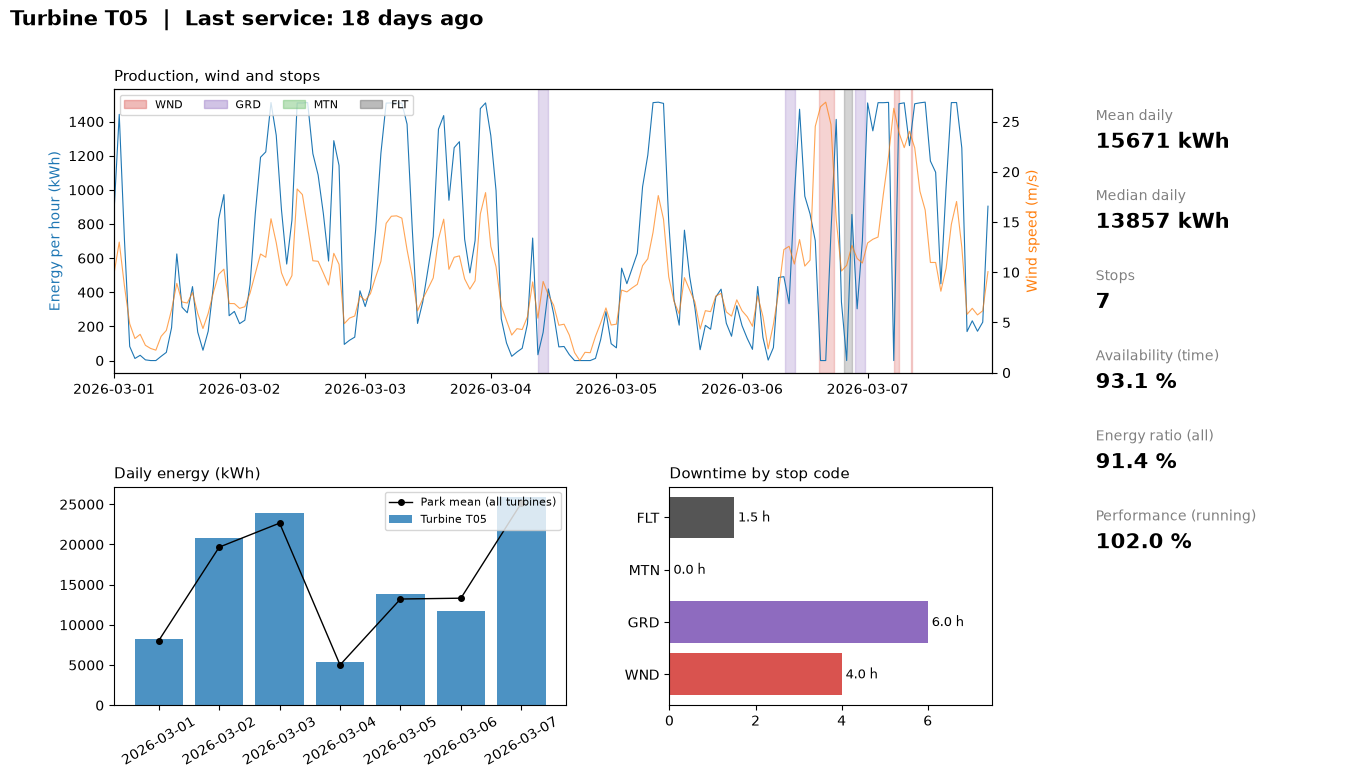

In [58]:
turbine_card("T05")

- T05 had the highest performance ratio while running (not counting stops)
- However, there was a period where the turbine performance was 75% of the expected (while the whole park was at 100%). This can point to the need of the service. After this reduced energy period, there were high winds (high wind shut down) and later the turbine had a hydraulic technical fault, even though the last service was just 18 days ago
- Turbine performance while running was near the expected energy, even though there was a low performance period - if there is a fault and it can be fixed, the perfomance of this turbine would be even better

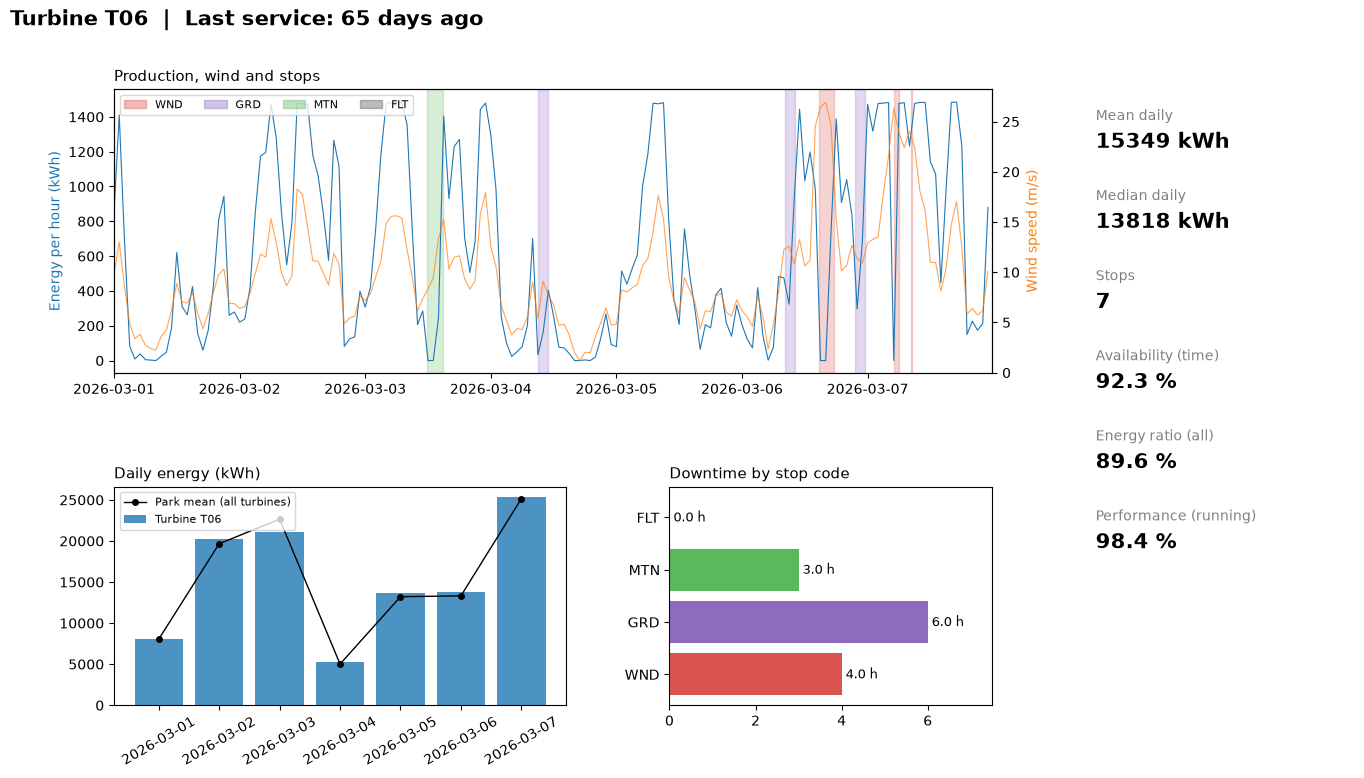

In [59]:
turbine_card("T06")

- T06 had the longest running time of all, the least stops (5)
- The performance was the second worst, and since the last service was 65 days ago, this can point to the need of the maintenance

## Park level performance

In [60]:
df_park_stops = df_stops[df_stops["stop_code"].isin(["GRD", "WND"])]
selected_stops = df_park_stops.drop_duplicates(subset="timestamp_start")
selected_stops

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
4,2026-03-04 09:00:00,2026-03-04 11:00:00,T01,GRD,Park-level grid limitation
14,2026-03-06 08:10:00,2026-03-06 10:10:00,T01,GRD,Park-level grid limitation
20,2026-03-06 14:40:00,2026-03-06 17:30:00,T01,WND,High wind shutdown
27,2026-03-06 21:30:00,2026-03-06 23:30:00,T01,GRD,Park-level grid limitation
33,2026-03-07 05:00:00,2026-03-07 06:00:00,T01,WND,High wind shutdown
39,2026-03-07 08:20:00,2026-03-07 08:30:00,T01,WND,"Extreme wind (added: wind > 25 m/s, all turbin..."


In park level, there were 5 stops:
- 3 due to grid limitation
- 2 due high wind

These would be the external losses, that we cannot control. The reasons may be that the energy supply is higher than we need (can be during high wind) or external problems.

GRD: 3 stops


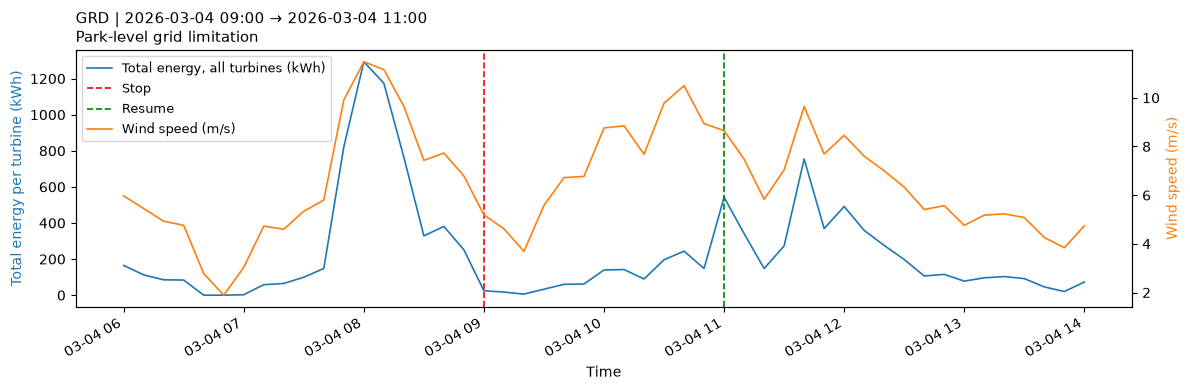

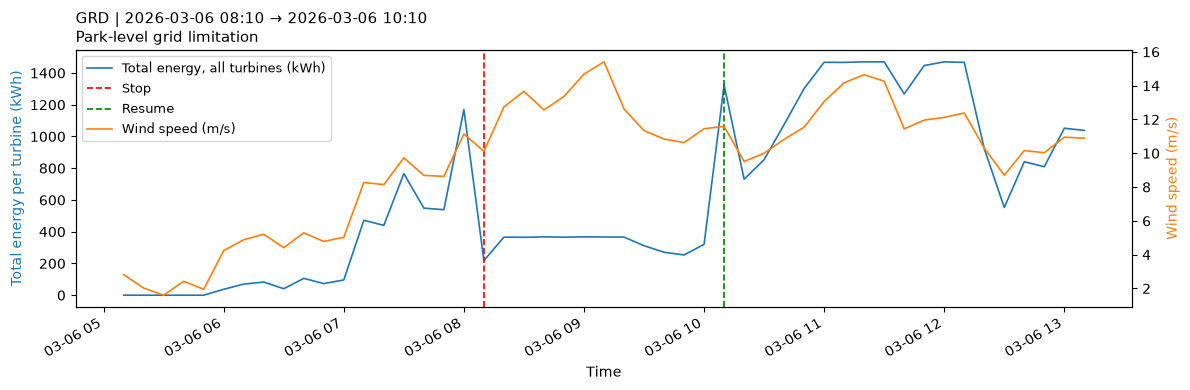

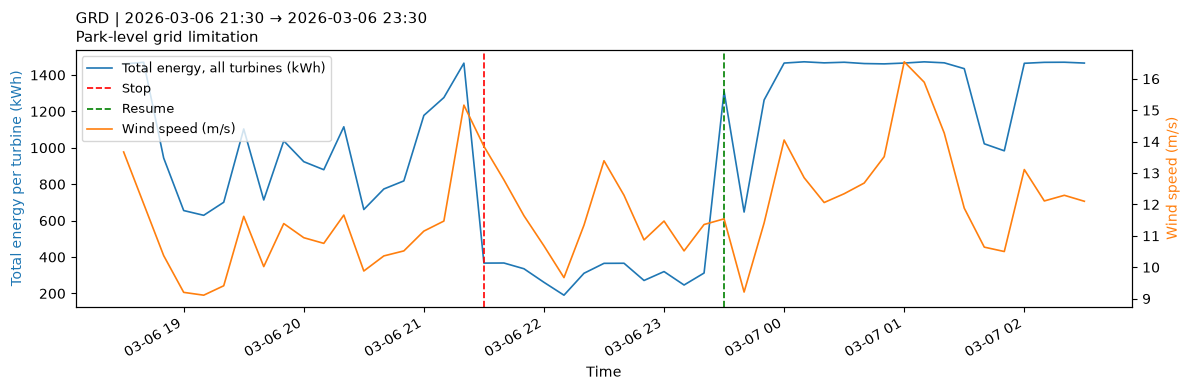

WND: 3 stops


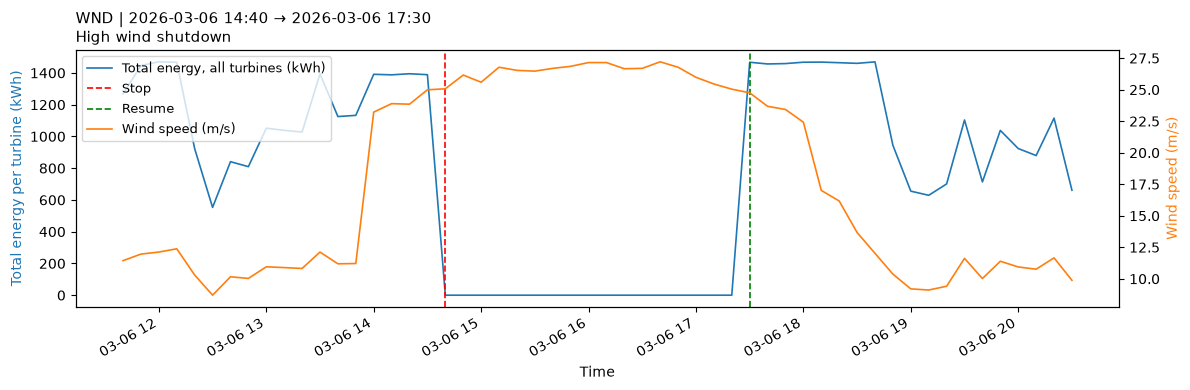

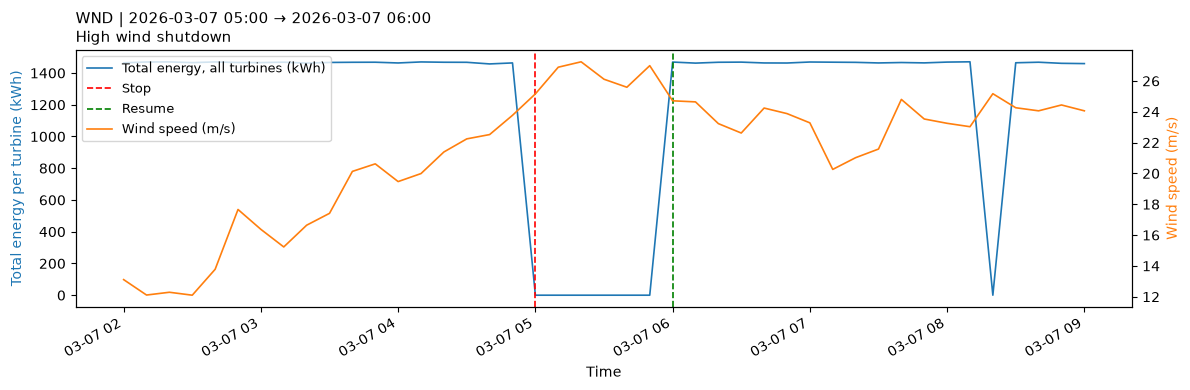

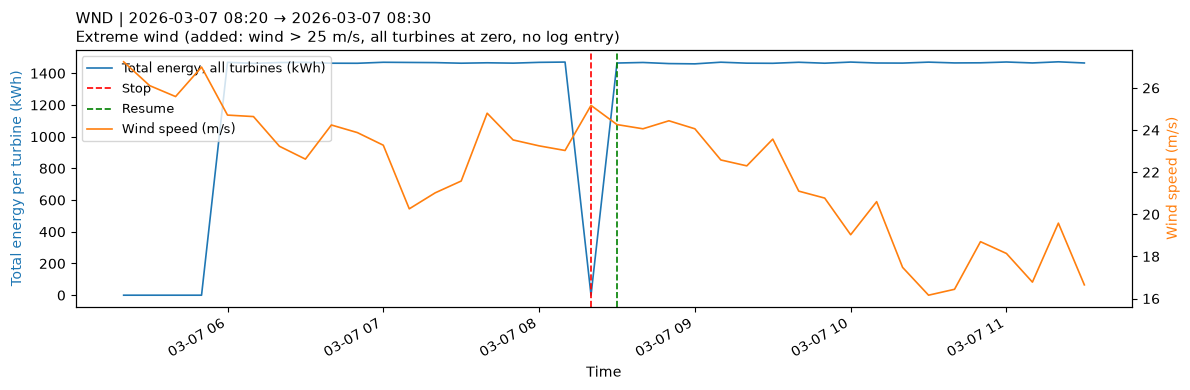

In [61]:
def plot_stop(stop, margin=pd.Timedelta("3h")):
    start = stop["timestamp_start"]
    end = stop["timestamp_end"]
    window_end = (end if pd.notna(end) else start + pd.Timedelta("1D")) + margin
    window_start = start - margin

    prod = (df_prod[df_prod["timestamp"].between(window_start, window_end)]
                   .groupby("timestamp", as_index=False)["energy_kwh"].sum())
    wind = df_weather[df_weather["timestamp"].between(window_start, window_end)]

    fig, ax1 = plt.subplots(figsize=(12, 4))
    ax1.plot(prod["timestamp"], prod["energy_kwh"], color="tab:blue", linewidth=1.2,
             label="Total energy, all turbines (kWh)")
    ax1.set_ylabel("Total energy per turbine (kWh)", color="tab:blue")

    ax2 = ax1.twinx()
    ax2.plot(wind["timestamp"], wind["wind_speed_ms"], color="tab:orange", linewidth=1.2, label="Wind speed (m/s)")
    ax2.set_ylabel("Wind speed (m/s)", color="tab:orange")
    ax2.grid(False)

    ax1.axvline(start, color="red", linestyle="--", linewidth=1.2, label="Stop")
    if pd.notna(end):
        ax1.axvline(end, color="green", linestyle="--", linewidth=1.2, label="Resume")

    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=9)

    end_txt = end.strftime("%Y-%m-%d %H:%M") if pd.notna(end) else "no end time"
    ax1.set_title(f"{stop['stop_code']} | {start:%Y-%m-%d %H:%M} → {end_txt}\n{stop['comment']}",
                  fontsize=11, loc="left")
    ax1.set_xlabel("Time")
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()


for code in ["GRD", "WND"]:
    subset = selected_stops[selected_stops["stop_code"] == code].sort_values("timestamp_start")
    print(f"{code}: {len(subset)} stops")
    for _, stop in subset.iterrows():
        plot_stop(stop)

What's the wind speed threshold for shutting down turbines?

In [62]:
duckdb.sql("""
    SELECT s.timestamp_start,
           s.timestamp_end,
           s.stop_code,
           arg_min(w.wind_speed_ms, w.timestamp) AS wind_at_start,
           arg_max(w.wind_speed_ms, w.timestamp) AS wind_at_end,
           MIN(w.wind_speed_ms)                  AS wind_min,
           MAX(w.wind_speed_ms)                  AS wind_max
    FROM selected_stops AS s
    LEFT JOIN df_weather AS w
           ON w.timestamp BETWEEN s.timestamp_start AND s.timestamp_end
    GROUP BY s.timestamp_start, s.timestamp_end, s.stop_code
    ORDER BY s.stop_code, s.timestamp_start
""").df()

,timestamp_start,timestamp_end,stop_code,wind_at_start,wind_at_end,wind_min,wind_max
0,2026-03-04 09:00:00,2026-03-04 11:00:00,GRD,5.19,8.65,3.69,10.50
1,2026-03-06 08:10:00,2026-03-06 10:10:00,GRD,10.11,11.59,10.11,15.41
2,2026-03-06 21:30:00,2026-03-06 23:30:00,GRD,13.85,11.54,9.67,13.85
3,2026-03-06 14:40:00,2026-03-06 17:30:00,WND,25.07,24.75,24.75,27.21
4,2026-03-07 05:00:00,2026-03-07 06:00:00,WND,25.16,24.71,24.71,27.24
5,2026-03-07 08:20:00,2026-03-07 08:30:00,WND,25.17,24.26,24.26,25.17


Has the wind been > 25 m/s where the stop hasn't been recorded?

In [63]:
duckdb.sql("""
    SELECT w.timestamp, w.wind_speed_ms
    FROM df_weather AS w
    WHERE w.wind_speed_ms > 25
      AND NOT EXISTS (
          SELECT 1
          FROM selected_stops AS s
          WHERE s.stop_code = 'WND'
            AND w.timestamp BETWEEN s.timestamp_start
                                AND COALESCE(s.timestamp_end, s.timestamp_start + INTERVAL 1 DAY)
      )
    ORDER BY w.timestamp
""").df()

,timestamp,wind_speed_ms


The whole park is shut down when the wind is >25 m/s for more than 10 mins.

### Key findings

Overall:
- energy production is growing steeply when the wind speed is increasing, until the energy production reaches 250 kWh per 10 min
- The whole park ratio of actual / expected energy production is 0.991 (during time without stops)
- Double counting is avoided by calculating losses per turbine and 10-minute interval and assigning each interval exactly one cause, duplicates were removed, no intervals had overlapping events

Needs service:
- Turbines with the lowest ratio of actual / expected energy production: T04 (0.912) and T06 (0.984) had the longest time since their last service (120 and 65 days).
- T05 ran at 72–75% of expected output for ~1.5 hours, despite being serviced 18 days ago. Otherwise it performed as expected, worth checking if additional service is needed
- T04 lost 4.5 hours of performance due to a fault - 3 stops (its service was long time ago - points to a need of service). Had the worst performance while running
- T06's performance was the second worst, and since the last service was 65 days ago, this can point to the need of the maintenance, but the T04 service is a priority

Park level:
- There was 10.3 % less energy produced than expected
- The most energy production was lost due to factors that are not in control - high winds (46.8%) and grid limitations (33.1%).
- Technical faults and scheduled maintenance caused 14% of energy loss.
- The whole park is shut down when the wind is >25 m/s for more than 10 mins.

| Cause | Estimated energy loss (kWh) | % of total loss |
|---|---:|---:|
| Extreme wind conditions (WND) | 36,360 | 48.8 |
| Grid limitation (GRD) | 26,518 | 35.6 |
| Technical faults (FLT) | 6,547 | 8.8 |
| Scheduled maintenance (MTN) | 3,864 | 5.2 |
| Unexplained | 1,199 | 1.6 |
| **Total** | **74,488** | **100** |